# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : RUSLAN ABDUL GANI LUBIS
- NIM   : 241011400691
- Kelas : Reg B

In [1]:
import pandas as pd
df = pd.read_csv('Ads_Data.csv')
print(df.head())

   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3


## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [2]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 91    # isi dengan 2 digit terakhir NIM Anda

In [3]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3
Jumlah baris: 40
Shape X: (40, 1) | Shape y: (40,)


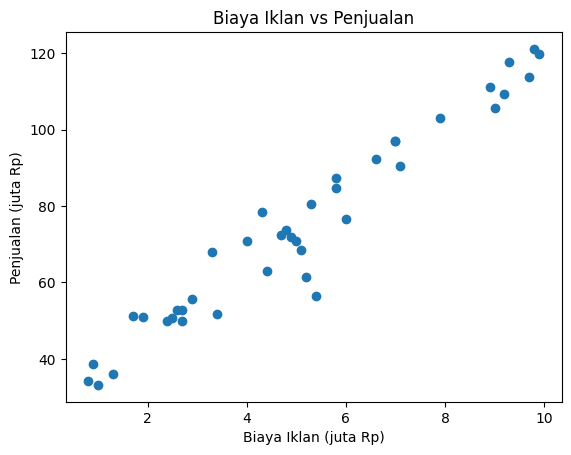

In [4]:
# Jawaban A1
df = pd.read_csv('Ads_Data.csv')
print(df.head())
print("Jumlah baris:", len(df))

X = df['BiayaIklan'].values.reshape(-1, 1)   # dibuat 2 dimensi (n, 1)
y = df['Penjualan'].values

print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.scatter(X, y)
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [5]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print('X_train:', X_train.shape)
print('X_test: ', X_test.shape)
print('y_train:', y_train.shape)
print('y_test: ', y_test.shape)

X_train: (32, 1)
X_test:  (8, 1)
y_train: (32,)
y_test:  (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [6]:
# Salin LinearRegression dari materi
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_

In [7]:
# Salin LinearRegressionGD dari materi
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient

            loss = np.mean((y - X_b @ beta) ** 2)
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_

In [8]:
# Jawaban A3
model = LinearRegression()
model.fit(X_train, y_train)

b0 = model.intercept_
b1 = model.coefficients_[0]
print("Intercept (b0):", b0)
print("Koefisien (b1):", b1)
print(f"Persamaan: y = {b0:.3f} + {b1:.3f} * x")

Intercept (b0): 27.579732842186335
Koefisien (b1): 9.180295435710324
Persamaan: y = 27.580 + 9.180 * x


**Jawaban A3 (interpretasi):**
Nilai b1 = 9,180 artinya setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sekitar 9,18 juta Rp (dengan asumsi hubungan linear). Nilai b0 = 27,580 artinya perkiraan penjualan ketika biaya iklan 0, yaitu sekitar 27,58 juta Rp, atau bisa dianggap penjualan dasar tanpa iklan. Tapi data terkecil kita biaya iklan 0,8 juta, jadi tafsiran b0 ini hanya perkiraan kasar.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [9]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

hasil = pd.DataFrame({
    'Train': [mae(y_train, pred_train), mse(y_train, pred_train), rmse(y_train, pred_train), r2_score(y_train, pred_train)],
    'Test':  [mae(y_test, pred_test),  mse(y_test, pred_test),  rmse(y_test, pred_test),  r2_score(y_test, pred_test)]
}, index=['MAE', 'MSE', 'RMSE', 'R2'])
hasil

,Train,Test
MAE,4.127903,6.129113
MSE,33.096789,48.323393
RMSE,5.752981,6.951503
R2,0.950724,0.869660


**Jawaban A4 (analisis):**
RMSE data testing = 6,95 artinya rata-rata kesalahan prediksi model sekitar 6,95 juta Rp, atau sekitar 9% dari rata-rata penjualan (74,27 juta). R² testing = 0,870 artinya sekitar 87% variasi penjualan bisa dijelaskan oleh biaya iklan, dan R² training lebih tinggi (0,951). Menurut saya model ini sudah cukup baik karena R² testing tinggi dan selisih RMSE training (5,75) dengan testing tidak terlalu jauh. Penurunan di data testing masih wajar karena datanya hanya 8 titik.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

Normal equation -> b0: 27.579732842186335  b1: 9.180295435710324
GD lr=0.001 -> b0: 18.37821896367172  b1: 10.548428282461678
GD lr=0.02 -> b0: 27.579732811435207  b1: 9.180295440282578


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:136: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_11305/4264724914.py:26: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - X_b @ beta) ** 2)
/tmp/ipykernel_11305/4264724914.py:23: RuntimeWarning: overflow encountered in matmul
  gradient = X_b.T @ (y_hat - y) / len(y)
/tmp/ipykernel_11305/4264724914.py:24: RuntimeWarning: invalid value encountered in subtract
  beta = beta - self.learning_rate * gradient


GD lr=0.1 -> b0: nan  b1: nan


/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


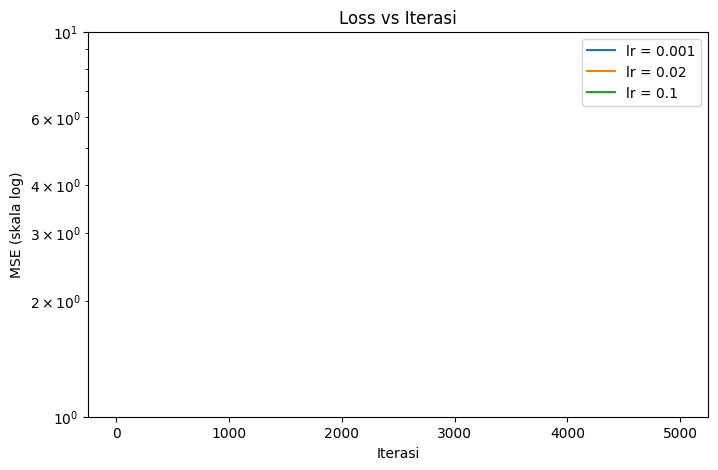

In [10]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
models_gd = {}

print("Normal equation -> b0:", model.intercept_, " b1:", model.coefficients_[0])
for lr in learning_rates:
    m = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    m.fit(X_train, y_train)
    models_gd[lr] = m
    print(f"GD lr={lr} -> b0: {m.intercept_}  b1: {m.coefficients_[0]}")

plt.figure(figsize=(8, 5))
for lr in learning_rates:
    plt.plot(models_gd[lr].loss_history_, label=f'lr = {lr}')
plt.yscale('log')
plt.xlabel('Iterasi')
plt.ylabel('MSE (skala log)')
plt.title('Loss vs Iterasi')
plt.legend()
plt.show()

**Jawaban A5 (analisis):**
Hasil normal equation: b0 = 27,580 dan b1 = 9,180. Dengan learning rate 0,001, hasilnya b0 = 18,378 dan b1 = 10,548, masih jauh dari normal equation, jadi terlalu lambat dan belum konvergen setelah 5000 iterasi karena langkah update-nya terlalu kecil. Learning rate 0,02 menghasilkan b0 = 27,5797 dan b1 = 9,1803, hampir sama dengan normal equation, jadi ini yang paling pas. Learning rate 0,1 gagal (hasilnya nan) karena langkahnya terlalu besar sehingga melompati titik minimum dan errornya makin membesar di tiap iterasi (divergen). RuntimeWarning overflow artinya angkanya sudah terlalu besar untuk ditampung komputer.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

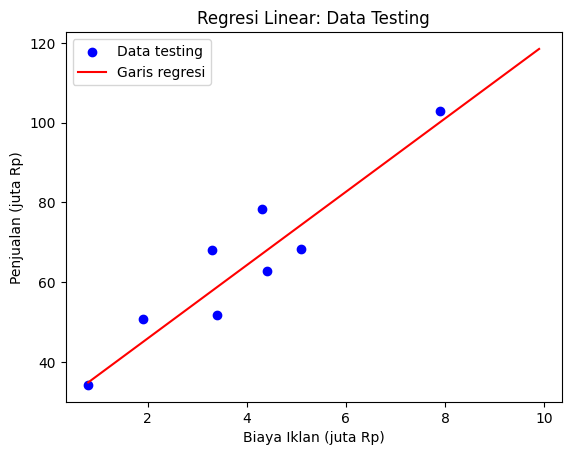

[ 68.8910623   91.84180089 137.74327807]


In [11]:
# Jawaban A6
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)

plt.scatter(X_test, y_test, c='blue', label='Data testing')
plt.plot(x_line, model.predict(x_line), c='red', label='Garis regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.title('Regresi Linear: Data Testing')
plt.legend()
plt.show()

input_baru = np.array([[4.5], [7], [12]])
print(model.predict(input_baru))

**Jawaban A6 (analisis):**
Prediksi penjualan untuk biaya iklan 4,5 juta, 7 juta, dan 12 juta masing-masing sekitar 68,89 juta, 91,84 juta, dan 137,74 juta. Prediksi untuk 12 juta adalah ekstrapolasi karena data kita hanya sampai biaya iklan 9,9 juta, dan hasilnya (137,74) bahkan lebih besar dari penjualan tertinggi di data (121,1). Hasil ini kurang bisa dipercaya karena model hanya mengasumsikan hubungan linear terus berlaku, padahal di dunia nyata kenaikan penjualan bisa melambat, misalnya karena pasar sudah jenuh. Prediksi di dalam rentang data (4,5 dan 7 juta) jauh lebih bisa dipercaya.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1
Jumlah baris: 60
Jumlah Spam: 25
Jumlah Bukan Spam: 35
Shape X: (60, 2) | Shape y: (60,)


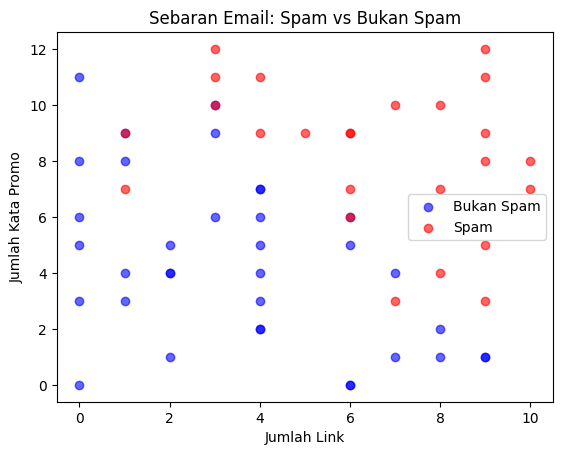

In [12]:
# Jawaban B1
email = pd.read_csv('Email_Data.csv')
print(email.head())
print("Jumlah baris:", len(email))
print("Jumlah Spam:", (email['Spam'] == 1).sum())
print("Jumlah Bukan Spam:", (email['Spam'] == 0).sum())

X = email[['JumlahLink', 'KataPromo']].values   # 2 fitur
y = email['Spam'].values                        # label 0/1
print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.scatter(X[y == 0, 0], X[y == 0, 1], c='blue', alpha=0.6, label='Bukan Spam')
plt.scatter(X[y == 1, 0], X[y == 1, 1], c='red', alpha=0.6, label='Spam')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.title('Sebaran Email: Spam vs Bukan Spam')
plt.legend()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

In [13]:
# Salin LogisticRegression, accuracy_score, confusion_matrix dari materi
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta = beta - self.learning_rate * gradient

            p = np.clip(p, 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict_proba(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self._sigmoid(self.intercept_ + X @ self.coefficients_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


def accuracy_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))

    return np.array([[tn, fp],
                     [fn, tp]])

X_train: (45, 2) | X_test: (15, 2)
Intercept: -14.181214172285005
Koefisien: 1.3226447197659181 1.042572837415828
z = -14.181 + 1.323 * JumlahLink + 1.043 * KataPromo
P(Spam) = sigmoid(z)


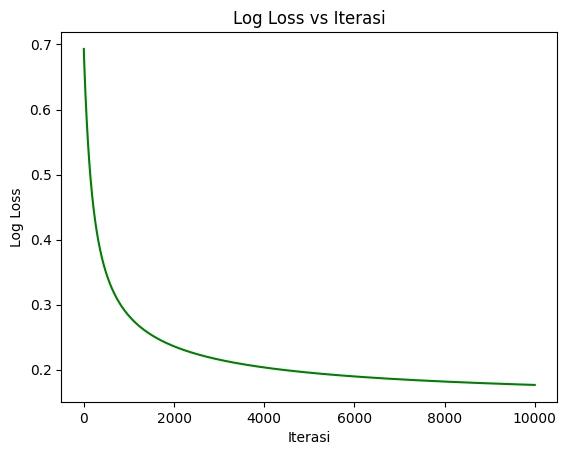

In [14]:
# Jawaban B2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
print('X_train:', X_train.shape, '| X_test:', X_test.shape)   # (45, 2) dan (15, 2)

clf = LogisticRegression(learning_rate=0.1, n_iterations=10000)
clf.fit(X_train, y_train)

b0 = clf.intercept_
b1, b2 = clf.coefficients_
print('Intercept:', b0)
print('Koefisien:', b1, b2)
print(f'z = {b0:.3f} + {b1:.3f} * JumlahLink + {b2:.3f} * KataPromo')
print('P(Spam) = sigmoid(z)')

plt.plot(clf.loss_history_, c='g')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.title('Log Loss vs Iterasi')
plt.show()

**Jawaban B2 (analisis):**
Persamaannya: z = -14,181 + 1,323 × JumlahLink + 1,043 × KataPromo, dengan P(Spam) = sigmoid(z). Kedua koefisien positif, artinya makin banyak link dan kata promo, makin besar peluang email dianggap spam. Pada grafik, log loss turun tajam di awal dari sekitar 0,693 lalu melandai, sehingga bisa dibilang sudah turun dan hampir stabil, dengan loss akhir sekitar 0,177.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [15]:
# Jawaban B3
def precision_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

y_pred = clf.predict(X_test)

print('Accuracy :', accuracy_score(y_test, y_pred))
print('Confusion Matrix [[TN, FP], [FN, TP]]:')
print(confusion_matrix(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall   :', recall_score(y_test, y_pred))
print('F1-score :', f1_score(y_test, y_pred))

Accuracy : 0.8666666666666667
Confusion Matrix [[TN, FP], [FN, TP]]:
[[8 0]
 [2 5]]
Precision: 1.0
Recall   : 0.7142857142857143
F1-score : 0.8333333333333333


**Jawaban B3 (analisis):**
Hasil di data testing: accuracy 0,867, precision 1,000, recall 0,714, dan F1-score 0,833, dengan confusion matrix TN = 8, FP = 0, FN = 2, TP = 5. False positive (FP) adalah email biasa yang salah dikira spam, dan false negative (FN) adalah email spam yang lolos ke inbox. Menurut saya FP lebih merugikan karena email penting (misalnya info kuliah atau pekerjaan) bisa masuk folder spam dan tidak terbaca, sedangkan FN hanya membuat inbox kemasukan satu spam yang bisa dihapus manual. Di hasil saya FP = 0 dan FN = 2.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Boundary: KataPromo = -(-14.181 + 1.323 * JumlahLink) / 1.043


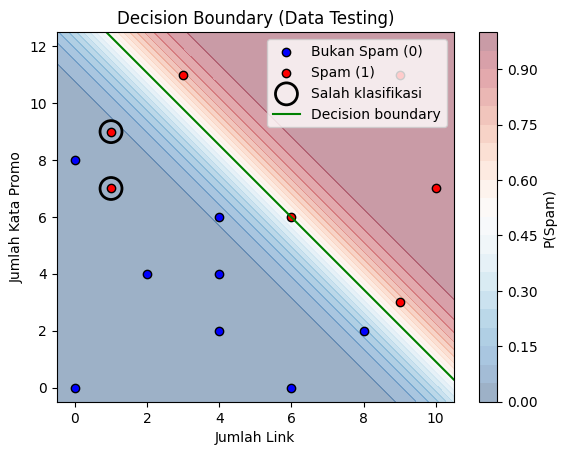

Data testing yang salah [JumlahLink, KataPromo], label asli, prediksi:
[1 9] 1 0
[1 7] 1 0


In [16]:
# Jawaban B4
print(f'Boundary: KataPromo = -({b0:.3f} + {b1:.3f} * JumlahLink) / {b2:.3f}')

x1, x2 = np.meshgrid(np.linspace(-0.5, 10.5, 200), np.linspace(-0.5, 12.5, 200))
grid = np.c_[x1.ravel(), x2.ravel()]
proba = clf.predict_proba(grid).reshape(x1.shape)

x1_line = np.linspace(-0.5, 10.5, 100)
x2_line = -(b0 + b1 * x1_line) / b2

salah = (y_test != y_pred)

plt.contourf(x1, x2, proba, levels=20, cmap='RdBu_r', alpha=0.4)
plt.colorbar(label='P(Spam)')
plt.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c='blue', edgecolors='k', label='Bukan Spam (0)')
plt.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c='red', edgecolors='k', label='Spam (1)')
plt.scatter(X_test[salah, 0], X_test[salah, 1], s=250, facecolors='none', edgecolors='black',
            linewidths=2, label='Salah klasifikasi')
plt.plot(x1_line, x2_line, c='g', label='Decision boundary')
plt.xlim(-0.5, 10.5)
plt.ylim(-0.5, 12.5)
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.title('Decision Boundary (Data Testing)')
plt.legend(loc='upper right')
plt.show()

print('Data testing yang salah [JumlahLink, KataPromo], label asli, prediksi:')
for xi, yt, yp in zip(X_test[salah], y_test[salah], y_pred[salah]):
    print(xi, yt, yp)

**Jawaban B4 (analisis):**
Persamaan decision boundary: KataPromo = -(-14,181 + 1,323 × JumlahLink) / 1,043, atau sekitar KataPromo = 13,60 - 1,27 × JumlahLink. Pada grafik ada 2 data testing yang salah diklasifikasikan (ditandai lingkaran hitam), yaitu [JumlahLink = 1, KataPromo = 9] dan [JumlahLink = 1, KataPromo = 7]. Keduanya sebenarnya spam tetapi diprediksi bukan spam (FN), karena jumlah link-nya hanya 1 sehingga posisinya berada di bawah garis boundary. Artinya model kurang bagus mengenali spam yang kata promonya banyak tapi linknya sedikit.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [17]:
# Jawaban B5
proba_test = clf.predict_proba(X_test)
baris = []
for t in [0.3, 0.5, 0.7]:
    pred_t = (proba_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_t).ravel()
    baris.append({'Threshold': t, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                  'Precision': precision_score(y_test, pred_t),
                  'Recall': recall_score(y_test, pred_t)})
pd.DataFrame(baris)

,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,8,0,2,5,1.0,0.714286
1,0.5,8,0,2,5,1.0,0.714286
2,0.7,8,0,3,4,1.0,0.571429


**Jawaban B5 (analisis):**
Pada threshold 0,3 dan 0,5 hasilnya sama (FP = 0, FN = 2, precision 1,000, recall 0,714), sedangkan pada threshold 0,7 FN naik jadi 3 dan recall turun menjadi 0,571 (precision tetap 1,000). Menaikkan threshold membuat model lebih "pelit" memberi label spam, sehingga FP cenderung turun (precision naik atau tetap) tetapi FN naik (recall turun). Sebaliknya, menurunkan threshold membuat lebih banyak email dilabeli spam, sehingga recall naik tapi FP bisa bertambah. Berdasarkan B3 (FP lebih merugikan), saya memilih threshold 0,5 karena hasilnya sama dengan 0,3 di data testing tapi lebih aman dari risiko email biasa salah masuk spam, dan tidak menurunkan recall seperti 0,7.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [18]:
# Jawaban B6
THRESHOLD = 0.5   # GANTI sesuai threshold pilihanmu di B5

email_baru = pd.DataFrame({'Email': ['E1', 'E2', 'E3', 'E4'],
                           'JumlahLink': [1, 5, 9, 2],
                           'KataPromo': [2, 6, 10, 11]})
X_baru = email_baru[['JumlahLink', 'KataPromo']].values

email_baru['P(Spam)'] = clf.predict_proba(X_baru).round(3)
email_baru['Kelas'] = np.where(clf.predict_proba(X_baru) >= THRESHOLD, 'Spam', 'Bukan Spam')
email_baru

,Email,JumlahLink,KataPromo,P(Spam),Kelas
0,E1,1,2,0.000,Bukan Spam
1,E2,5,6,0.212,Bukan Spam
2,E3,9,10,1.000,Spam
3,E4,2,11,0.483,Bukan Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?



```
# This is formatted as code
```

**Jawaban C1:**
Logistic Regression disebut klasifikasi karena hasil akhirnya berupa kelas (misalnya Spam atau Bukan Spam), bukan angka kontinu. Namanya tetap "regression" karena di dalamnya ada perhitungan linear z = b + m1·X1 + m2·X2 seperti pada Linear Regression. Masalahnya, nilai z bisa berapa saja, sedangkan kita butuh probabilitas antara 0 dan 1. Di sinilah fungsi sigmoid berperan, yaitu mengubah z menjadi probabilitas (yang keluar di predict_proba). Setelah itu probabilitas dibandingkan dengan threshold (default 0,5) untuk menentukan kelas 0 atau 1.

**Jawaban C2:**
Normal equation menghitung koefisien langsung dalam satu langkah memakai rumus matriks β = (XᵀX)⁻¹Xᵀy, jadi hasilnya eksak tanpa perlu mengatur learning rate. Gradient descent mencari koefisien secara bertahap dengan mengulang update beta = beta − α·gradient sebanyak n_iterations kali. Pada Soal A5 terlihat hasil gradient descent bergantung pada learning rate: terlalu kecil lambat konvergen, terlalu besar bisa divergen. Gradient descent sebaiknya dipakai kalau datanya besar atau fiturnya banyak (karena menghitung invers matriks jadi mahal), atau kalau modelnya tidak punya rumus langsung seperti Logistic Regression.

**Jawaban C3:**
Model harus dievaluasi pada data testing karena data training sudah dipakai model untuk belajar, sehingga nilainya cenderung terlalu bagus dan tidak menggambarkan kemampuan model sebenarnya. Data testing berperan seperti data baru yang belum pernah dilihat model. Overfitting adalah kondisi ketika model terlalu "menghafal" data training (termasuk noise-nya), sehingga performanya bagus di training tapi turun di data testing. Pada hasil saya, R² training = 0,951 dan R² testing = 0,870, serta RMSE training 5,75 dan testing 6,95. Selisihnya ada tapi tidak besar, jadi model ini belum menunjukkan overfitting yang parah. Penurunan itu juga wajar karena data testing hanya 8 titik sehingga hasilnya mudah bergeser.

**Jawaban C4:**
Linear Regression menghasilkan output berupa angka kontinu (misalnya penjualan), jadi cocok diukur dengan MSE, yaitu rata-rata kuadrat selisih antara nilai sebenarnya dan prediksi. Logistic Regression menghasilkan probabilitas untuk label 0 atau 1, jadi yang diukur adalah seberapa yakin model terhadap kelas yang benar. Log loss memberi hukuman sangat besar kalau model yakin tapi salah, misalnya label aslinya 1 tetapi probabilitas prediksinya hanya 0,01. Selain itu, kalau MSE dipakai bersama sigmoid, bentuk loss-nya jadi tidak cembung sehingga gradient descent lebih sulit menemukan solusi yang baik, sedangkan log loss lebih cocok untuk kasus ini.

**Jawaban C5:**
Perbedaannya berasal dari random_state yang saya pakai, yaitu dua digit terakhir NIM, yang berbeda dengan teman. Nilai random_state menentukan urutan acak data di train_test_split, sehingga isi data training dan testing berbeda untuk tiap mahasiswa. Karena model dilatih dan dites pada pembagian data yang berbeda, koefisien dan metrik evaluasinya (R², accuracy, dan lainnya) ikut berbeda walaupun dataset dan algoritmanya sama. Efeknya cukup terasa karena datanya sedikit, misalnya data testing pada Bagian B hanya 15 email, sehingga satu kesalahan prediksi saja sudah menggeser accuracy cukup jauh.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [19]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# ===== Linear Regression =====
ads = pd.read_csv('Ads_Data.csv')
Xa = ads[['BiayaIklan']].values
ya = ads['Penjualan'].values
Xa_train, Xa_test, ya_train, ya_test = train_test_split(Xa, ya, test_size=0.2, random_state=RANDOM_STATE)

lin_sendiri = LinearRegression().fit(Xa_train, ya_train)
lin_sk = SkLinearRegression().fit(Xa_train, ya_train)

print('Intercept  -> sendiri:', lin_sendiri.intercept_, '| sklearn:', lin_sk.intercept_)
print('Koefisien  -> sendiri:', lin_sendiri.coefficients_[0], '| sklearn:', lin_sk.coef_[0])
print('R2 test    -> sendiri:', r2_score(ya_test, lin_sendiri.predict(Xa_test)),
      '| sklearn:', r2_score(ya_test, lin_sk.predict(Xa_test)))

# ===== Logistic Regression =====
em = pd.read_csv('Email_Data.csv')
Xe = em[['JumlahLink', 'KataPromo']].values
ye = em['Spam'].values
Xe_train, Xe_test, ye_train, ye_test = train_test_split(Xe, ye, test_size=0.25, random_state=RANDOM_STATE)

log_sendiri = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xe_train, ye_train)
log_sk = SkLogisticRegression(max_iter=10000).fit(Xe_train, ye_train)               # pengaturan default
log_sk_c = SkLogisticRegression(C=1e6, max_iter=10000).fit(Xe_train, ye_train)      # regularisasi dibuat sangat lemah

def ringkas(nama, b0, b1, b2, y_pred):
    return {'Model': nama, 'Intercept': b0, 'Koef JumlahLink': b1, 'Koef KataPromo': b2,
            'Accuracy': accuracy_score(ye_test, y_pred),
            'Precision': precision_score(ye_test, y_pred),
            'Recall': recall_score(ye_test, y_pred)}

tabel = pd.DataFrame([
    ringkas('Sendiri', log_sendiri.intercept_, *log_sendiri.coefficients_, log_sendiri.predict(Xe_test)),
    ringkas('sklearn default', log_sk.intercept_[0], *log_sk.coef_[0], log_sk.predict(Xe_test)),
    ringkas('sklearn C=1e6', log_sk_c.intercept_[0], *log_sk_c.coef_[0], log_sk_c.predict(Xe_test)),
])
tabel

Intercept  -> sendiri: 27.579732842186335 | sklearn: 27.579732842186388
Koefisien  -> sendiri: 9.180295435710324 | sklearn: 9.18029543571032
R2 test    -> sendiri: 0.8696604360729364 | sklearn: 0.8696604360729367


,Model,Intercept,Koef JumlahLink,Koef KataPromo,Accuracy,Precision,Recall
0,Sendiri,-14.181214,1.322645,1.042573,0.866667,1.0,0.714286
1,sklearn default,-14.319440,1.324163,1.053154,0.800000,1.0,0.571429
2,sklearn C=1e6,-25.955881,2.506023,1.852864,0.866667,1.0,0.714286


In [20]:
# Uji konvergensi: apakah koefisien model saya mendekati sklearn (C=1e6) kalau iterasinya ditambah?
hasil_iter = []
for n_iter in [10000, 100000, 1000000]:
    m = LogisticRegression(learning_rate=0.1, n_iterations=n_iter).fit(Xe_train, ye_train)
    hasil_iter.append({'Iterasi': n_iter,
                       'Intercept': m.intercept_,
                       'Koef JumlahLink': m.coefficients_[0],
                       'Koef KataPromo': m.coefficients_[1],
                       'Log Loss Akhir': m.loss_history_[-1]})

hasil_iter.append({'Iterasi': 'sklearn C=1e6',
                   'Intercept': log_sk_c.intercept_[0],
                   'Koef JumlahLink': log_sk_c.coef_[0][0],
                   'Koef KataPromo': log_sk_c.coef_[0][1],
                   'Log Loss Akhir': None})
pd.DataFrame(hasil_iter)

,Iterasi,Intercept,Koef JumlahLink,Koef KataPromo,Log Loss Akhir
0,10000,-14.181214,1.322645,1.042573,0.176584
1,100000,-24.364773,2.345105,1.743604,0.156815
2,1000000,-25.955914,2.506028,1.852869,0.156590
3,sklearn C=1e6,-25.955881,2.506023,1.852864,NaN


**Jawaban Bonus (analisis):**

*Linear Regression.* Hasil implementasi saya dan sklearn identik: intercept 27,580, koefisien 9,180, dan R² testing sama-sama 0,870. Ini wajar karena keduanya menyelesaikan masalah yang sama (meminimalkan MSE) dan sama-sama punya solusi eksak lewat normal equation, jadi tidak ada faktor yang membuat hasilnya berbeda.

*Logistic Regression.* Di sini ada perbedaan. Dengan pengaturan default, sklearn memberi intercept -14,319 dengan koefisien 1,324 dan 1,053, accuracy 0,800 dan recall 0,571, sedangkan implementasi saya memberi intercept -14,181 dengan koefisien 1,323 dan 1,043, accuracy 0,867 dan recall 0,714. Penyebab utamanya, LogisticRegression sklearn secara default memakai regularisasi L2 dengan C = 1,0, yaitu penalti yang menahan koefisien agar tidak terlalu besar, sedangkan implementasi saya tidak punya penalti. Saat saya melemahkan regularisasi dengan C = 1e6, koefisien sklearn menjadi jauh lebih besar (intercept -25,956; koefisien 2,506 dan 1,853), dan accuracy serta recall-nya kembali sama dengan model saya (0,867 dan 0,714).

Koefisien model saya (-14,181; 1,323; 1,043) ternyata tidak sama dengan hasil sklearn C = 1e6, padahal sama-sama tanpa penalti. Penyebabnya, data ini hampir terpisah sempurna secara linear (tidak ada false positive pada data testing), sehingga solusi optimalnya punya koefisien yang sangat besar dan loss terus turun pelan-pelan. Gradient descent saya dengan 10.000 iterasi berhenti sebelum sampai ke sana, sedangkan sklearn memakai solver yang berbeda dan lebih cepat konvergen. Jadi model saya sebenarnya belum konvergen penuh, dan itu terlihat dari koefisiennya yang lebih kecil.

Selisih accuracy antar model (0,867 vs 0,800) hanya setara satu email dari 15 data testing, jadi lebih mencerminkan kecilnya data testing daripada perbedaan kualitas model yang besar.



*Pembuktian konvergensi.* Untuk membuktikan bahwa perbedaan koefisien disebabkan iterasi yang belum cukup, saya melatih ulang model dengan 10.000, 100.000, dan 1.000.000 iterasi. Hasilnya koefisien terus membesar, dari intercept -14,18 (10.000 iterasi) menjadi -25,96 (1.000.000 iterasi), dan koefisien JumlahLink serta KataPromo menjadi 2,506 dan 1,853, hampir sama dengan hasil sklearn C = 1e6. Log loss juga turun dari 0,1766 menjadi 0,1568 dan 0,1566, dan penurunan terakhir sangat kecil, yang menandakan model sudah hampir konvergen. Artinya implementasi saya sebenarnya benar, hanya saja pada 10.000 iterasi gradient descent belum konvergen penuh karena datanya hampir terpisah sempurna, sehingga loss turun sangat lambat menuju solusi dengan koefisien besar.